# Char-CNN + TextCNN 이중 탐지 모델

두 모델을 서로 다른 목적으로 학습합니다.

- **Char-CNN:** 정상(0) / 비속어·우회 유해 표현(1) 이진 분류
- **TextCNN:** 정상(0) / 피싱·광고(2) 이진 분류

TextCNN은 PyTorch 학습 과정에서 라벨 2를 내부적으로 1로 변환합니다. 예측 결과를 표시할 때는 다시 피싱·광고로 해석합니다.

네 개 CSV를 병합한 뒤 각 모델에 해당하는 라벨의 데이터를 전부 사용합니다. 표본 추출로 데이터 수를 줄이지 않습니다. 클래스 불균형은 손실 함수의 클래스 가중치로 보정합니다. 각 모델은 최대 50 Epoch 학습하며, 검증 데이터의 F1-score가 가장 높았던 가중치를 저장합니다. 성능 비교 모델은 따로 두지 않습니다.

## 실행 전 확인
- 노트북과 같은 프로젝트 폴더에 `dataset` 폴더를 두고 `dataset1.csv`~`dataset4.csv`를 넣어 주세요.
- 위에서 아래 순서대로 실행합니다.
- 두 모델은 각자의 데이터와 정답 라벨로 따로 학습합니다.


In [3]:
import os
import re
import random
import time
import copy
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from tqdm.auto import tqdm
from IPython.display import display


c:\AIproject\DL_middle\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
# 난수 고정 및 실행 장치 설정
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("사용 장치:", device)
print("GPU 사용 가능:", torch.cuda.is_available())


사용 장치: cpu
GPU 사용 가능: False


In [5]:
# 데이터 및 모델 저장 폴더 설정
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "dataset"
OUTPUT_DIR = BASE_DIR / "models"

# 모델 저장 폴더 생성
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 데이터 폴더 확인
print("프로젝트 폴더:", BASE_DIR)
print("데이터 폴더:", DATA_DIR)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"데이터 폴더를 찾을 수 없습니다: {DATA_DIR}")

# CSV 파일 확인
csv_files = list(DATA_DIR.glob("*.csv"))
print("CSV 파일 목록:", [p.name for p in csv_files])

if len(csv_files) != 4:
    raise FileNotFoundError(
        f"CSV 파일 4개가 필요합니다. 현재 발견된 파일: {len(csv_files)}개"
    )

프로젝트 폴더: c:\AIproject\DL_middle
데이터 폴더: c:\AIproject\DL_middle\dataset
CSV 파일 목록: ['dataset1.csv', 'dataset2.csv', 'dataset3.csv', 'dataset4.csv']


In [30]:
def load_csv(file_path):
    encodings = ["utf-8", "cp949", "euc-kr"]
    for encoding in encodings:
        try:
            data = pd.read_csv(file_path, encoding=encoding)
            print(f"{file_path.name} 로드 성공: {encoding}")
            return data
        except UnicodeDecodeError:
            continue
    raise ValueError(f"파일 인코딩 확인 필요: {file_path.name}")


In [31]:
# CSV 4개 불러오기
df1 = load_csv(DATA_DIR / "dataset1.csv")
df2 = load_csv(DATA_DIR / "dataset2.csv")
df3 = load_csv(DATA_DIR / "dataset3.csv")
df4 = load_csv(DATA_DIR / "dataset4.csv")

print("dataset1:", df1.shape, df1.columns.tolist())
print("dataset2:", df2.shape, df2.columns.tolist())
print("dataset3:", df3.shape, df3.columns.tolist())
print("dataset4:", df4.shape, df4.columns.tolist())


dataset1.csv 로드 성공: cp949
dataset2.csv 로드 성공: utf-8
dataset3.csv 로드 성공: utf-8
dataset4.csv 로드 성공: cp949
dataset1: (200000, 2) ['content', 'label']
dataset2: (11010, 2) ['text', 'label']
dataset3: (19009, 3) ['index', 'content', 'class']
dataset4: (934, 2) ['LABEL', 'TEXT']


In [32]:
# 컬럼명 및 라벨 통일
def find_column(df, candidates):
    for col in candidates:
        if col in df.columns:
            return col
    return None


def standardize_dataset(df, dataset_name, text_candidates, label_candidates, label_mapping):
    text_col = find_column(df, text_candidates)
    label_col = find_column(df, label_candidates)

    if text_col is None or label_col is None:
        raise ValueError(
            f"{dataset_name} 컬럼을 찾을 수 없습니다. "
            f"현재 컬럼: {df.columns.tolist()}"
        )

    result = df[[text_col, label_col]].copy()
    result.columns = ["content", "original_label"]
    result["content"] = result["content"].astype(str).str.strip()
    result["original_label"] = pd.to_numeric(result["original_label"], errors="coerce")
    result = result.dropna(subset=["original_label"])
    result["original_label"] = result["original_label"].astype(int)
    result["label"] = result["original_label"].map(label_mapping)

    unknown = result[result["label"].isna()]
    if len(unknown) > 0:
        raise ValueError(
            f"{dataset_name}에 매핑되지 않은 라벨이 있습니다: "
            f"{unknown['original_label'].unique()}"
        )

    result["label"] = result["label"].astype(int)
    result["source"] = dataset_name
    result = result[["content", "label", "source"]]
    result = result[(result["content"] != "") & (result["content"].str.lower() != "nan")]
    print(f"{dataset_name} 통일 완료: {len(result):,}건")
    return result


In [33]:
# 원본 데이터의 라벨을 통일
# dataset1: 0 정상, 1 유해 표현
# dataset2: 0 정상, 1 우회 유해 표현
# dataset3: 1 정상, 2 피싱·광고, 3 배송 정상
# dataset4: 0 정상, 1 피싱·광고

data1 = standardize_dataset(
    df1, "dataset1",
    ["content", "text", "message", "sms", "내용", "문자"],
    ["label", "class", "target", "라벨"],
    {0: 0, 1: 1}
)
data2 = standardize_dataset(
    df2, "dataset2",
    ["content", "text", "message", "sms", "내용", "문자"],
    ["label", "class", "target", "라벨"],
    {0: 0, 1: 1}
)
data3 = standardize_dataset(
    df3, "dataset3",
    ["content", "text", "TEXT", "message", "sms", "내용", "문자"],
    ["class", "label", "LABEL", "target", "라벨"],
    {1: 0, 2: 2, 3: 0}
)
data4 = standardize_dataset(
    df4, "dataset4",
    ["content", "TEXT", "text", "message", "sms", "내용", "문자"],
    ["LABEL", "label", "class", "target", "라벨"],
    {0: 0, 1: 2}
)


dataset1 통일 완료: 200,000건
dataset2 통일 완료: 11,010건
dataset3 통일 완료: 19,009건
dataset4 통일 완료: 934건


In [34]:
# 데이터 병합 및 정리
df = pd.concat([data1, data2, data3, data4], ignore_index=True)

# 동일 문장이 서로 다른 라벨을 가진 경우 해당 문장 제외
label_counts = df.groupby("content")["label"].nunique()
conflict_texts = label_counts[label_counts > 1].index
print("라벨 충돌 문장 수:", len(conflict_texts))
df = df[~df["content"].isin(conflict_texts)].copy()

# 동일 문장 중복 제거
df = df.drop_duplicates(subset=["content", "label"]).reset_index(drop=True)

# 사용자 정의 비속어 데이터 추가
badword_texts = [
    "시발 진짜 짜증 나네",
    "아 진짜 시발 뭐 하는 거야",
    "오늘 진짜 기분 더럽네 시발",
    "시발 왜 이렇게 안 되는 거야",
    "이게 말이 되냐 시발",
    "병신 같은 소리 하지 마",
    "너 진짜 병신이냐",
    "병신아 정신 좀 차려",
    "아 병신 진짜 답답하네",
    "저런 병신 같은 행동은 뭐냐",
    "시1발 진짜 화나네",
    "시!발 뭐 하는 거야",
    "시@발 진짜 어이없네",
    "ㅅㅂ 너무 짜증 난다",
    "ㅅㅂ 이게 뭐야",
    "ㅂㅅ 같은 짓 하지 마",
    "너 완전 ㅂㅅ이네",
    "시 발 진짜 왜 이래",
    "병 신 같은 소리 하네",
    "시이발 진짜 못 참겠다",
    "개시발 진짜 최악이다",
    "존나 짜증 나네",
    "존나 어이없다",
    "개짜증 나네 진짜",
    "미친놈아 그만해",
    "미친년아 뭐 하는 거야",
    "지랄하지 마라",
    "지랄하고 있네 진짜",
    "개소리 좀 그만해",
    "닥쳐 좀",
    "꺼져 버려",
    "엿 먹어라",
    "좆같은 상황이네",
    "좆됐다 진짜",
    "또라이 같은 소리 하네",
    "한심한 새끼네",
    "이 멍청한 새끼야",
    "개같은 하루네",
    "아 씨발 진짜",
    "씨1발 뭐냐",
    "ㅅㅂㅅㅂ 진짜 화난다",
    "ㅂㅅ아 그만 좀 해",
    "병신아 왜 그러냐",
    "시발놈아 꺼져",
    "개병신 같은 소리 하네",
    "진짜 존나 답답하다",
    "니가 뭔데 지랄이야",
    "아오 시발 미치겠네",
    "이딴 개소리를 하냐",
    "진짜 좆같아서 못 하겠다"
]

badword_df = pd.DataFrame({
    "content": badword_texts,
    "label": 1,
    "source": "custom_badword"
})

# 기존 데이터와 중복되는 비속어 문장은 기존 행을 제거
# 새로 지정한 라벨 1을 적용
df = df[~df["content"].isin(badword_texts)].copy()

# 비속어 데이터 추가
df = pd.concat(
    [df, badword_df],
    ignore_index=True
)

# 최종 중복 제거
df = df.drop_duplicates(
    subset=["content", "label"]
).reset_index(drop=True)

print("비속어 데이터 추가 완료")
print("추가한 비속어:", len(badword_df))
print("최종 전체 데이터:", len(df))
print(df["label"].value_counts().sort_index())



라벨 충돌 문장 수: 0
비속어 데이터 추가 완료
추가한 비속어: 50
최종 전체 데이터: 227848
label
0    114189
1    105555
2      8104
Name: count, dtype: int64


## 1. 모델별 학습 데이터 분리

두 모델은 서로 다른 이진 분류 데이터셋을 사용합니다.

- Char-CNN: 원래 라벨 0과 1만 사용
- TextCNN: 원래 라벨 0과 2만 사용

각 데이터셋은 클래스별 개수를 맞춘 뒤 각각 학습/검증/테스트로 나눕니다.


In [35]:
# 각 모델에 필요한 라벨만 선택하고, 해당 라벨의 데이터는 전부 사용
def make_binary_dataset(source_df, labels, model_name):
    subset = source_df[source_df["label"].isin(labels)].copy()

    counts = subset["label"].value_counts().sort_index()
    if len(counts) != 2:
        raise ValueError(
            f"{model_name}: 필요한 두 라벨이 모두 있는지 확인하세요. "
            f"현재 분포: {counts.to_dict()}"
        )

    # 표본 추출이나 클래스별 개수 제한 없이 모든 데이터 사용
    subset = subset.sample(frac=1, random_state=SEED).reset_index(drop=True)

    print(f"\n{model_name} 전체 데이터 수: {len(subset):,}")
    print("라벨별 데이터 수:")
    print(subset["label"].value_counts().sort_index())
    return subset

# Char-CNN: 전체 데이터 중 정상(0)과 유해 표현(1)을 모두 사용
df_char = make_binary_dataset(df, [0, 1], "Char-CNN")

# TextCNN: 전체 데이터 중 정상(0)과 피싱·광고(2)를 모두 사용
df_text = make_binary_dataset(df, [0, 2], "TextCNN")

df_char.to_csv(OUTPUT_DIR / "charcnn_dataset.csv", index=False, encoding="utf-8-sig")
df_text.to_csv(OUTPUT_DIR / "textcnn_dataset.csv", index=False, encoding="utf-8-sig")



Char-CNN 전체 데이터 수: 219,744
라벨별 데이터 수:
label
0    114189
1    105555
Name: count, dtype: int64

TextCNN 전체 데이터 수: 122,293
라벨별 데이터 수:
label
0    114189
2      8104
Name: count, dtype: int64


In [63]:
# 모델별로 학습/검증/테스트 데이터 분리
def split_binary_dataset(data, positive_original_label, model_name):

    # 일반 NumPy 배열로 변환
    X = np.asarray(data["content"].astype(str).tolist(), dtype=object)
    labels = np.asarray(data["label"].tolist(), dtype=np.int64)

    y = (labels == positive_original_label).astype(np.int64)

    # 사용자 정의 비속어 데이터 구분
    if model_name == "Char-CNN":
        custom_mask = (
            data["source"].values == "custom_badword"
        )

        # 사용자 정의 비속어 데이터
        X_custom = X[custom_mask]
        y_custom = y[custom_mask]

        # 기존 데이터
        X_original = X[~custom_mask]
        y_original = y[~custom_mask]

        # 기존 데이터만 학습/검증/테스트 분리
        X_train_val, X_test, y_train_val, y_test = train_test_split(
            X_original, y_original,
            test_size=0.2,
            random_state=SEED,
            stratify=y_original
        )

        X_train, X_val, y_train, y_val = train_test_split(
            X_train_val, y_train_val,
            test_size=0.2,
            random_state=SEED,
            stratify=y_train_val
        )

        # 사용자 정의 비속어 50개는 전부 학습 데이터에 추가
        X_train = np.concatenate([X_train, X_custom])
        y_train = np.concatenate([y_train, y_custom])

    else:
        # TextCNN은 기존 방식 유지
        X_train_val, X_test, y_train_val, y_test = train_test_split(
            X, y,
            test_size=0.2,
            random_state=SEED,
            stratify=y
        )

        X_train, X_val, y_train, y_val = train_test_split(
            X_train_val, y_train_val,
            test_size=0.2,
            random_state=SEED,
            stratify=y_train_val
        )

    # 학습 데이터 섞기
    rng = np.random.default_rng(SEED)
    train_indices = rng.permutation(len(X_train))

    X_train = X_train[train_indices]
    y_train = y_train[train_indices]

    print(f"\n[{model_name}]")

    for split_name, labels_split in [
        ("학습", y_train),
        ("검증", y_val),
        ("테스트", y_test)
    ]:
        print(
            f"{split_name}: {len(labels_split):,}건 | "
            f"정상(0): {(labels_split == 0).sum():,}건 | "
            f"탐지 대상(1): {(labels_split == 1).sum():,}건"
        )

    if model_name == "Char-CNN":
        print(
            "사용자 정의 비속어 학습 데이터:",
            sum(
                str(x).strip() in set(data.loc[custom_mask, "content"])
                for x in X_train
            )
        )

    return X_train, X_val, X_test, y_train, y_val, y_test

# CharCNN 데이터 분리
(X_train_char, X_val_char, X_test_char,
 y_train_char, y_val_char, y_test_char) = split_binary_dataset(
    df_char, 1, "Char-CNN"
)

# TextCNN 데이터 분리
(X_train_text, X_val_text, X_test_text,
 y_train_text, y_val_text, y_test_text) = split_binary_dataset(
    df_text, 2, "TextCNN"
)


[Char-CNN]
학습: 140,654건 | 정상(0): 73,081건 | 탐지 대상(1): 67,573건
검증: 35,151건 | 정상(0): 18,270건 | 탐지 대상(1): 16,881건
테스트: 43,939건 | 정상(0): 22,838건 | 탐지 대상(1): 21,101건
사용자 정의 비속어 학습 데이터: 50

[TextCNN]
학습: 78,267건 | 정상(0): 73,081건 | 탐지 대상(1): 5,186건
검증: 19,567건 | 정상(0): 18,270건 | 탐지 대상(1): 1,297건
테스트: 24,459건 | 정상(0): 22,838건 | 탐지 대상(1): 1,621건


In [64]:
# 학습 설정
MAX_CHAR_LENGTH = 300
MAX_WORD_LENGTH = 128
BATCH_SIZE = 64
EPOCHS = 50
LEARNING_RATE = 0.001
EARLY_STOPPING_PATIENCE = 5

print(f"최대 Epoch: {EPOCHS}, Early Stopping patience: {EARLY_STOPPING_PATIENCE}")


최대 Epoch: 50, Early Stopping patience: 5


In [65]:
# 문자/단어 토큰화 및 어휘 사전
def tokenize_words(text):
    return re.findall(r"[가-힣]+|[a-zA-Z]+|\d+|[^\s]", str(text).lower())


def build_vocab(texts, mode="word"):
    counter = Counter()
    for text in texts:
        tokens = list(str(text)) if mode == "char" else tokenize_words(text)
        counter.update(tokens)

    vocab = {"<PAD>": 0, "<UNK>": 1}
    for token, count in counter.items():
        if count >= 1:
            vocab[token] = len(vocab)
    return vocab


def encode_text(text, vocab, max_length, mode="word"):
    tokens = list(str(text)) if mode == "char" else tokenize_words(text)
    ids = [vocab.get(token, vocab["<UNK>"]) for token in tokens[:max_length]]
    ids += [vocab["<PAD>"]] * (max_length - len(ids))
    return ids

# 각 모델은 자기 학습 데이터만으로 어휘 사전을 생성
char_vocab = build_vocab(X_train_char, mode="char")
word_vocab = build_vocab(X_train_text, mode="word")
print("Char 어휘 수:", len(char_vocab))
print("Word 어휘 수:", len(word_vocab))


Char 어휘 수: 5771
Word 어휘 수: 274098


In [66]:
# 모델별 텍스트를 숫자로 변환
X_train_char_ids = np.array([encode_text(x, char_vocab, MAX_CHAR_LENGTH, "char") for x in X_train_char])
X_val_char_ids = np.array([encode_text(x, char_vocab, MAX_CHAR_LENGTH, "char") for x in X_val_char])
X_test_char_ids = np.array([encode_text(x, char_vocab, MAX_CHAR_LENGTH, "char") for x in X_test_char])

X_train_text_ids = np.array([encode_text(x, word_vocab, MAX_WORD_LENGTH, "word") for x in X_train_text])
X_val_text_ids = np.array([encode_text(x, word_vocab, MAX_WORD_LENGTH, "word") for x in X_val_text])
X_test_text_ids = np.array([encode_text(x, word_vocab, MAX_WORD_LENGTH, "word") for x in X_test_text])

print("Char-CNN:", X_train_char_ids.shape, X_val_char_ids.shape, X_test_char_ids.shape)
print("TextCNN:", X_train_text_ids.shape, X_val_text_ids.shape, X_test_text_ids.shape)


Char-CNN: (140654, 300) (35151, 300) (43939, 300)
TextCNN: (78267, 128) (19567, 128) (24459, 128)


In [67]:
# 데이터 로더 생성
def make_loader(X, y, batch_size=BATCH_SIZE, shuffle=False):
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.long),
        torch.tensor(y, dtype=torch.long)
    )
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=0)

char_train_loader = make_loader(X_train_char_ids, y_train_char, shuffle=True)
char_val_loader = make_loader(X_val_char_ids, y_val_char)
char_test_loader = make_loader(X_test_char_ids, y_test_char)

text_train_loader = make_loader(X_train_text_ids, y_train_text, shuffle=True)
text_val_loader = make_loader(X_val_text_ids, y_val_text)
text_test_loader = make_loader(X_test_text_ids, y_test_text)
print("두 모델의 데이터 로더 생성 완료")


두 모델의 데이터 로더 생성 완료


In [68]:
# Char-CNN: 문자 단위 분류 모델
class CharCNN(nn.Module):
    def __init__(self, vocab_size, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, 64, padding_idx=0)
        self.convs = nn.ModuleList([
            nn.Conv1d(64, 128, kernel_size=k) for k in [3, 4, 5]
        ])
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128 * 3, num_classes)

    def forward(self, x):
        x = self.embedding(x).transpose(1, 2)
        features = []
        for conv in self.convs:
            out = torch.relu(conv(x))
            out = torch.max_pool1d(out, out.size(2)).squeeze(2)
            features.append(out)
        x = self.dropout(torch.cat(features, dim=1))
        return self.fc(x)


In [69]:
# TextCNN: 단어 단위 분류 모델
class TextCNN(nn.Module):
    def __init__(self, vocab_size, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, 128, padding_idx=0)
        self.convs = nn.ModuleList([
            nn.Conv1d(128, 128, kernel_size=k) for k in [2, 3, 4]
        ])
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128 * 3, num_classes)

    def forward(self, x):
        x = self.embedding(x).transpose(1, 2)
        features = []
        for conv in self.convs:
            out = torch.relu(conv(x))
            out = torch.max_pool1d(out, out.size(2)).squeeze(2)
            features.append(out)
        x = self.dropout(torch.cat(features, dim=1))
        return self.fc(x)


In [70]:
# 이진 분류 평가 및 학습 함수
def calculate_binary_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }


def evaluate_model(model, data_loader, criterion):
    model.eval()
    total_loss = 0.0
    all_preds, all_actuals = [], []

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device)
            y_device = y_batch.to(device)
            outputs = model(X_batch)
            loss = criterion(outputs, y_device)
            total_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_actuals.extend(y_batch.numpy())

    return (
        total_loss / max(len(data_loader), 1),
        np.array(all_preds),
        np.array(all_actuals)
    )


def train_binary_model(model, train_loader, val_loader, test_loader,
                       model_name, model_filename):
    model = model.to(device)
    # 모든 데이터를 사용하되, 클래스 불균형은 가중치로 보정
    train_labels = train_loader.dataset.tensors[1].cpu().numpy()
    class_counts = np.bincount(train_labels, minlength=2)
    if np.any(class_counts == 0):
        raise ValueError(f"{model_name}: 학습 데이터에 두 클래스가 모두 있는지 확인하세요.")

    class_weights = len(train_labels) / (2.0 * class_counts)
    class_weights = torch.tensor(class_weights, dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    print(f"{model_name} 클래스 가중치 (0, 1): {class_weights.detach().cpu().numpy()}")

    history = []
    best_val_f1 = -1.0
    best_weights = copy.deepcopy(model.state_dict())
    best_epoch = 0
    wait = 0
    start_time = time.time()

    for epoch in range(EPOCHS):
        model.train()
        total_train_loss = 0.0

        for X_batch, y_batch in tqdm(
            train_loader, desc=f"{model_name} Epoch {epoch + 1}/{EPOCHS}"
        ):
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item()

        avg_train_loss = total_train_loss / max(len(train_loader), 1)
        avg_val_loss, val_preds, val_actuals = evaluate_model(
            model, val_loader, criterion
        )
        val_metrics = calculate_binary_metrics(val_actuals, val_preds)

        history.append({
            "Epoch": epoch + 1,
            "Train_Loss": avg_train_loss,
            "Val_Loss": avg_val_loss,
            "Val_Accuracy": val_metrics["Accuracy"],
            "Val_Precision": val_metrics["Precision"],
            "Val_Recall": val_metrics["Recall"],
            "Val_F1": val_metrics["F1-score"]
        })

        print(
            f"{model_name} | Epoch {epoch + 1}/{EPOCHS} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"Val F1: {val_metrics['F1-score']:.4f}"
        )

        # 검증 F1-score가 가장 높았던 가중치 저장
        if val_metrics["F1-score"] > best_val_f1:
            best_val_f1 = val_metrics["F1-score"]
            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            wait = 0
        else:
            wait += 1
            if wait >= EARLY_STOPPING_PATIENCE:
                print(f"{model_name}: Early Stopping (최적 Epoch: {best_epoch})")
                break

    # 가장 성능이 좋았던 Epoch의 가중치 복원
    model.load_state_dict(best_weights)

    # 테스트 데이터는 최적 모델 선택이 끝난 뒤 평가
    _, test_preds, test_actuals = evaluate_model(model, test_loader, criterion)
    elapsed = time.time() - start_time

    torch.save({
        "model_state_dict": model.state_dict(),
        "model_name": model_name,
        "best_epoch": best_epoch,
        "best_val_f1": best_val_f1
    }, OUTPUT_DIR / model_filename)

    print(
        f"{model_name} 학습 완료 | 최적 Epoch: {best_epoch} | "
        f"검증 F1: {best_val_f1:.4f} | 학습 시간: {elapsed:.1f}초"
    )

    return model, history, test_preds, test_actuals, elapsed, best_epoch


## 2. Char-CNN 학습: 비속어·우회 유해 표현 탐지

정상 문장은 0, 유해 표현 문장은 1로 학습합니다.


In [71]:
char_model = CharCNN(len(char_vocab))

char_model, char_history, char_test_preds, char_test_actuals, char_train_time, char_best_epoch = train_binary_model(
    char_model,
    char_train_loader,
    char_val_loader,
    char_test_loader,
    model_name="Char-CNN",
    model_filename="char_cnn_best.pt"
)


Char-CNN 클래스 가중치 (0, 1): [0.9623158 1.0407559]


Char-CNN Epoch 1/50: 100%|██████████| 2198/2198 [05:00<00:00,  7.30it/s]


Char-CNN | Epoch 1/50 | Train Loss: 0.1631 | Val Loss: 0.1093 | Val F1: 0.9522


Char-CNN Epoch 2/50: 100%|██████████| 2198/2198 [04:55<00:00,  7.43it/s]


Char-CNN | Epoch 2/50 | Train Loss: 0.1128 | Val Loss: 0.1007 | Val F1: 0.9547


Char-CNN Epoch 3/50: 100%|██████████| 2198/2198 [04:55<00:00,  7.43it/s]


... (15 outputs left out)

Char-CNN Epoch 11/50: 100%|██████████| 2198/2198 [06:53<00:00,  5.32it/s]


Char-CNN | Epoch 11/50 | Train Loss: 0.0325 | Val Loss: 0.1399 | Val F1: 0.9595


Char-CNN Epoch 12/50: 100%|██████████| 2198/2198 [06:37<00:00,  5.52it/s]


Char-CNN | Epoch 12/50 | Train Loss: 0.0290 | Val Loss: 0.1446 | Val F1: 0.9598
Char-CNN: Early Stopping (최적 Epoch: 7)
Char-CNN 학습 완료 | 최적 Epoch: 7 | 검증 F1: 0.9608 | 학습 시간: 4286.7초


## 3. TextCNN 학습: 광고·스미싱 탐지

원본 데이터의 정상 라벨 0과 피싱·광고 라벨 2를 사용합니다. 학습 함수에 넣을 때만 2를 이진 분류의 1로 변환했습니다.


In [72]:
text_model = TextCNN(len(word_vocab))

text_model, text_history, text_test_preds, text_test_actuals, text_train_time, text_best_epoch = train_binary_model(
    text_model,
    text_train_loader,
    text_val_loader,
    text_test_loader,
    model_name="TextCNN",
    model_filename="text_cnn_best.pt"
)


TextCNN 클래스 가중치 (0, 1): [0.53548115 7.545989  ]


TextCNN Epoch 1/50: 100%|██████████| 1223/1223 [07:54<00:00,  2.58it/s]


TextCNN | Epoch 1/50 | Train Loss: 0.0629 | Val Loss: 0.0277 | Val F1: 0.9853


TextCNN Epoch 2/50: 100%|██████████| 1223/1223 [07:24<00:00,  2.75it/s]


TextCNN | Epoch 2/50 | Train Loss: 0.0106 | Val Loss: 0.0340 | Val F1: 0.9218


TextCNN Epoch 3/50: 100%|██████████| 1223/1223 [06:13<00:00,  3.27it/s]


... (9 outputs left out)

TextCNN Epoch 8/50: 100%|██████████| 1223/1223 [06:08<00:00,  3.32it/s]


TextCNN | Epoch 8/50 | Train Loss: 0.0081 | Val Loss: 0.0746 | Val F1: 0.9727


TextCNN Epoch 9/50: 100%|██████████| 1223/1223 [06:02<00:00,  3.38it/s]


TextCNN | Epoch 9/50 | Train Loss: 0.0051 | Val Loss: 0.0844 | Val F1: 0.8909
TextCNN: Early Stopping (최적 Epoch: 4)
TextCNN 학습 완료 | 최적 Epoch: 4 | 검증 F1: 0.9857 | 학습 시간: 3523.9초


## 4. 각 모델의 테스트 결과 확인

두 모델을 서로 비교하는 것이 아니라, 각자 맡은 탐지 과제에서 얼마나 잘 작동하는지 따로 확인합니다.


[Char-CNN: 정상 vs 유해 표현]
최적 Epoch: 7
              precision    recall  f1-score   support

          정상     0.9653    0.9617    0.9635     22838
       유해 표현     0.9587    0.9626    0.9607     21101

    accuracy                         0.9621     43939
   macro avg     0.9620    0.9621    0.9621     43939
weighted avg     0.9621    0.9621    0.9621     43939



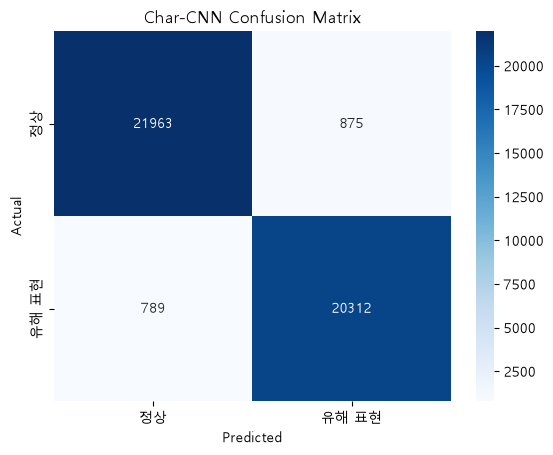

In [73]:
# 폰트지정
plt.rcParams['font.family'] = 'Malgun Gothic'

# Char-CNN 테스트 결과
print("[Char-CNN: 정상 vs 유해 표현]")
print("최적 Epoch:", char_best_epoch)
print(classification_report(
    char_test_actuals,
    char_test_preds,
    labels=[0, 1],
    target_names=["정상", "유해 표현"],
    digits=4,
    zero_division=0
))

cm_char = confusion_matrix(char_test_actuals, char_test_preds, labels=[0, 1])
sns.heatmap(
    cm_char, annot=True, fmt="d", cmap="Blues",
    xticklabels=["정상", "유해 표현"],
    yticklabels=["정상", "유해 표현"]
)
plt.title("Char-CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


[TextCNN: 정상 vs 피싱·광고]
최적 Epoch: 4
              precision    recall  f1-score   support

          정상     0.9989    0.9996    0.9993     22838
       피싱·광고     0.9938    0.9852    0.9895      1621

    accuracy                         0.9986     24459
   macro avg     0.9964    0.9924    0.9944     24459
weighted avg     0.9986    0.9986    0.9986     24459



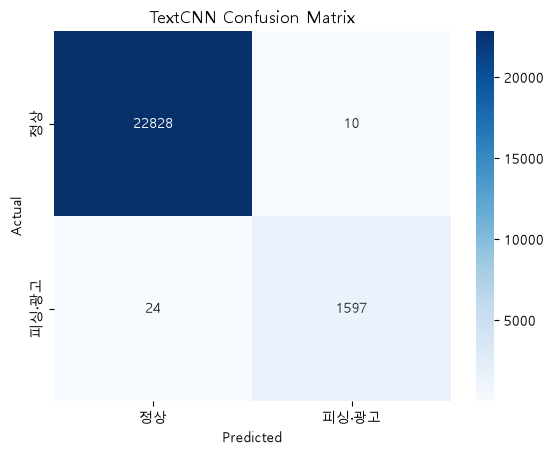

In [74]:
# TextCNN 테스트 결과
print("[TextCNN: 정상 vs 피싱·광고]")
print("최적 Epoch:", text_best_epoch)
print(classification_report(
    text_test_actuals,
    text_test_preds,
    labels=[0, 1],
    target_names=["정상", "피싱·광고"],
    digits=4,
    zero_division=0
))

cm_text = confusion_matrix(text_test_actuals, text_test_preds, labels=[0, 1])
sns.heatmap(
    cm_text, annot=True, fmt="d", cmap="Blues",
    xticklabels=["정상", "피싱·광고"],
    yticklabels=["정상", "피싱·광고"]
)
plt.title("TextCNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


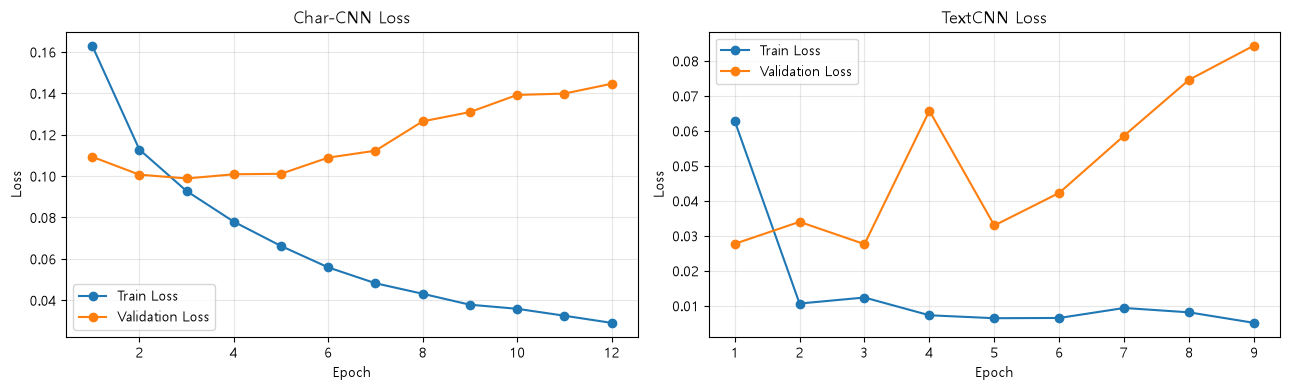

In [75]:
# 각 모델의 학습 과정 확인
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, history, name in [
    (axes[0], char_history, "Char-CNN"),
    (axes[1], text_history, "TextCNN")
]:
    history_df = pd.DataFrame(history)
    ax.plot(history_df["Epoch"], history_df["Train_Loss"], marker="o", label="Train Loss")
    ax.plot(history_df["Epoch"], history_df["Val_Loss"], marker="o", label="Validation Loss")
    ax.set_title(f"{name} Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [76]:
# 어휘 사전 및 전처리 설정 저장
import joblib

joblib.dump(char_vocab, OUTPUT_DIR / "char_vocab.pkl")
joblib.dump(word_vocab, OUTPUT_DIR / "word_vocab.pkl")

joblib.dump({
    "max_char_length": MAX_CHAR_LENGTH,
    "max_word_length": MAX_WORD_LENGTH,
    "char_labels": ["정상", "유해 표현"],
    "text_labels": ["정상", "피싱·광고"]
}, OUTPUT_DIR / "model_config.pkl")

print("모델 가중치와 어휘 사전 저장 완료:", OUTPUT_DIR)


모델 가중치와 어휘 사전 저장 완료: C:\AIproject\DL_middle\models


## 5. 직접 입력한 문장으로 두 모델 함께 사용하기

Char-CNN은 유해 표현 여부를, TextCNN은 피싱·광고 여부를 각각 판단합니다. 두 결과를 합쳐 최종 분류를 출력합니다.


In [85]:
def predict_message(text):
    if not isinstance(text, str) or not text.strip():
        print("문장을 입력해 주세요.")
        return None

    char_input = torch.tensor(
        [encode_text(text, char_vocab, MAX_CHAR_LENGTH, "char")],
        dtype=torch.long
    ).to(device)
    text_input = torch.tensor(
        [encode_text(text, word_vocab, MAX_WORD_LENGTH, "word")],
        dtype=torch.long
    ).to(device)

    char_model.eval()
    text_model.eval()

    with torch.no_grad():
        char_probs = torch.softmax(char_model(char_input), dim=1)[0]
        text_probs = torch.softmax(text_model(text_input), dim=1)[0]

    char_pred = int(torch.argmax(char_probs).item())
    text_pred = int(torch.argmax(text_probs).item())

    is_harmful = (char_pred == 1)
    is_phishing = (text_pred == 1)

    if is_harmful and is_phishing:
        final_result = "유해 표현 + 피싱·광고"
    elif is_harmful:
        final_result = "유해 표현"
    elif is_phishing:
        final_result = "피싱·광고"
    else:
        final_result = "정상"

    result = pd.DataFrame([
        {
            "모델": "Char-CNN",
            "탐지 대상": "비속어·유해 표현",
            "판정": "탐지" if is_harmful else "미탐지",
            "탐지 확률(%)": round(char_probs[1].item() * 100, 2)
        },
        {
            "모델": "TextCNN",
            "탐지 대상": "피싱·광고",
            "판정": "탐지" if is_phishing else "미탐지",
            "탐지 확률(%)": round(text_probs[1].item() * 100, 2)
        }
    ])

    print("입력 문장:", text)
    print("최종 결과:", final_result)
    display(result)
    return final_result, result

# 예시
predict_message("시발 정신 좀 차리라고 했지")


입력 문장: 시발 정신 좀 차리라고 했지
최종 결과: 유해 표현


,모델,탐지 대상,판정,탐지 확률(%)
0,Char-CNN,비속어·유해 표현,탐지,78.29
1,TextCNN,피싱·광고,미탐지,0.00


('유해 표현',
          모델      탐지 대상   판정  탐지 확률(%)
 0  Char-CNN  비속어·유해 표현   탐지     78.29
 1   TextCNN      피싱·광고  미탐지      0.00)